# S&P 500 sectors: return per unit of volatility, 2010-2024

**Question:** which sectors gave the best return for the volatility taken, and did it hold in each sub-period?

**What this notebook does**
1. Loads the two Databricks exports (weekly sector returns and the dbt mart).
2. Recomputes annualised return, volatility and return per volatility in pandas from the weekly table.
3. Reconciles pandas against the mart. The notebook stops if they disagree.
4. Draws one chart.

**Read before using any number**
- Only 172 of 502 companies have prices. Constituents are today's, so survivorship bias inflates absolute returns. Use the numbers to compare sectors only.
- Sector returns are an equal-weighted average of weekly close-to-close returns, which assumes weekly rebalancing.
- `return_per_volatility` is return divided by volatility. There is no risk-free rate, so it is not a Sharpe ratio.
- The set of stocks in a sector changes between sub-periods.
- This is a description of the past. It is not a forecast or investment advice.

In [11]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# "databricks" reads the live dbt tables. "csv" reads the committed snapshots in data/.
SOURCE = "csv"                      # change to "databricks" when you have the connection set up
SAVE_SNAPSHOT = False               # True: after a live read, overwrite the CSV snapshots in data/

WEEKLY_TABLE = "stocks.sp500_dev_marts.fct_sector_weekly_returns"
MART_TABLE = "stocks.sp500_dev_marts.mart_sector_risk_return"
WEEKLY_CSV = Path("../data/fct_sector_weekly_returns.csv")
MART_CSV = Path("../data/mart_sector_risk_return.csv")

WEEKS_PER_YEAR = 52
THIN_BELOW = 10          # sectors with fewer stocks than this are labelled thin
TOL = 1e-9               # reconciliation tolerance for return, volatility, ratio
SUB_PERIODS = ["2010-2014", "2015-2019", "2020-2024"]

## 1. Load and check the inputs

In [12]:
NUMERIC_WEEKLY = ["sector_weekly_return", "ticker_count"]
NUMERIC_MART = ["weeks", "avg_tickers", "annualised_return", "annualised_volatility", "return_per_volatility"]


def read_table(table):
    # Connection details come from environment variables. Never write them in the notebook.
    from databricks import sql
    with sql.connect(
        server_hostname=os.environ["DATABRICKS_HOST"],
        http_path=os.environ["DATABRICKS_HTTP_PATH"],
        access_token=os.environ["DATABRICKS_TOKEN"],
    ) as conn:
        with conn.cursor() as cur:
            cur.execute(f"SELECT * FROM {table}")
            return cur.fetchall_arrow().to_pandas()


if SOURCE == "databricks":
    weekly = read_table(WEEKLY_TABLE)
    mart = read_table(MART_TABLE)
elif SOURCE == "csv":
    weekly = pd.read_csv(WEEKLY_CSV)
    mart = pd.read_csv(MART_CSV)
else:
    raise ValueError(f"SOURCE must be 'databricks' or 'csv', got {SOURCE!r}")

# Live reads can return Decimal types, so force plain numbers.
weekly[NUMERIC_WEEKLY] = weekly[NUMERIC_WEEKLY].astype(float)
mart[NUMERIC_MART] = mart[NUMERIC_MART].astype(float)

# CSV exports store dates as 2010-01-11T00:00:00.000Z. Parse, then drop the timezone.
weekly["week_start_date"] = pd.to_datetime(weekly["week_start_date"], utc=True).dt.tz_localize(None)
weekly = weekly.sort_values(["business_sector", "week_start_date"]).reset_index(drop=True)
mart = mart.sort_values(["business_sector", "sub_period"]).reset_index(drop=True)

assert len(weekly) == 8580, len(weekly)
assert len(mart) == 44, len(mart)
assert weekly.isna().sum().sum() == 0, "nulls in weekly table"
assert not weekly.duplicated(["business_sector", "week_start_date"]).any(), "duplicate sector-weeks"
assert weekly["business_sector"].nunique() == 11

print("Source:", SOURCE)
print(weekly["week_start_date"].min().date(), "to", weekly["week_start_date"].max().date())
weekly.head()

Source: csv
2010-01-11 to 2024-12-16


,business_sector,week_start_date,sector_weekly_return,ticker_count
0,Basic Materials,2010-01-11,-0.016036,7.0
1,Basic Materials,2010-01-18,-0.045635,7.0
2,Basic Materials,2010-01-25,-0.024026,7.0
3,Basic Materials,2010-02-01,0.014163,7.0
4,Basic Materials,2010-02-08,0.023535,7.0


### 1b. Live data vs the committed snapshot
Only runs when `SOURCE = "databricks"`. It shows whether the models changed since the snapshot was taken.
If they differ, the memo and dashboard numbers need re-checking.

In [13]:
if SOURCE == "databricks":
    if WEEKLY_CSV.exists() and MART_CSV.exists():
        snap_w = pd.read_csv(WEEKLY_CSV)
        snap_w["week_start_date"] = pd.to_datetime(snap_w["week_start_date"], utc=True).dt.tz_localize(None)
        snap_w = snap_w.sort_values(["business_sector", "week_start_date"]).reset_index(drop=True)
        snap_m = pd.read_csv(MART_CSV).sort_values(["business_sector", "sub_period"]).reset_index(drop=True)

        w_diff = (weekly["sector_weekly_return"] - snap_w["sector_weekly_return"]).abs().max()
        m_diff = (mart["return_per_volatility"] - snap_m["return_per_volatility"]).abs().max()
        same_keys = (weekly[["business_sector", "week_start_date"]].equals(snap_w[["business_sector", "week_start_date"]])
                     and mart[["business_sector", "sub_period"]].equals(snap_m[["business_sector", "sub_period"]]))
        print("Same sectors and weeks as snapshot:", same_keys)
        print(f"Largest weekly-return difference vs snapshot: {w_diff:.3e}")
        print(f"Largest ratio difference vs snapshot:         {m_diff:.3e}")
    else:
        print("No snapshot found to compare against.")

    if SAVE_SNAPSHOT:
        WEEKLY_CSV.parent.mkdir(parents=True, exist_ok=True)
        weekly.to_csv(WEEKLY_CSV, index=False)
        mart.to_csv(MART_CSV, index=False)
        print("Snapshots overwritten.")
else:
    print("SOURCE is csv, nothing to compare.")

SOURCE is csv, nothing to compare.


## 2. Recompute in pandas

In [14]:
year = weekly["week_start_date"].dt.year
weekly["sub_period"] = np.select(
    [year <= 2014, year <= 2019], SUB_PERIODS[:2], default=SUB_PERIODS[2]
)
weekly["log_ret"] = np.log1p(weekly["sector_weekly_return"])


def summarise(g):
    mean_log = g["log_ret"].mean()
    vol = g["log_ret"].std(ddof=1) * np.sqrt(WEEKS_PER_YEAR)   # sample std, same as Spark stddev
    ret = np.exp(mean_log * WEEKS_PER_YEAR) - 1
    return pd.Series({
        "weeks": len(g),
        "avg_tickers": g["ticker_count"].mean(),
        "annualised_return": ret,
        "annualised_volatility": vol,
        "return_per_volatility": ret / vol,
    })


by_period = weekly.groupby(["business_sector", "sub_period"]).apply(summarise).reset_index()
full = weekly.groupby("business_sector").apply(summarise).reset_index().assign(sub_period="full")
calc = pd.concat([by_period, full], ignore_index=True)
calc.shape

(44, 7)

## 3. Reconcile against the dbt mart

In [15]:
chk = calc.merge(mart, on=["business_sector", "sub_period"], suffixes=("_pd", "_mart"), validate="one_to_one")
assert len(chk) == 44, "rows did not match one-to-one"

report = {}
for col in ["annualised_return", "annualised_volatility", "return_per_volatility"]:
    report[col] = (chk[f"{col}_pd"] - chk[f"{col}_mart"]).abs().max()
report["weeks"] = (chk["weeks_pd"] - chk["weeks_mart"]).abs().max()
# The mart stores avg_tickers as a whole number, so allow rounding (0.5).
report["avg_tickers (rounded in mart)"] = (chk["avg_tickers_pd"] - chk["avg_tickers_mart"]).abs().max()

print("Largest absolute difference, pandas vs mart")
for k, v in report.items():
    print(f"  {k:32s} {v:.3e}")

assert report["annualised_return"] < TOL
assert report["annualised_volatility"] < TOL
assert report["return_per_volatility"] < TOL
assert report["weeks"] == 0
assert report["avg_tickers (rounded in mart)"] <= 0.5
print("\nRECONCILED: pandas matches the mart.")

Largest absolute difference, pandas vs mart
  annualised_return                4.441e-16
  annualised_volatility            1.665e-16
  return_per_volatility            3.109e-15
  weeks                            0.000e+00
  avg_tickers (rounded in mart)    4.962e-01

RECONCILED: pandas matches the mart.


## 4. Does the ranking hold across sub-periods?
Rank 1 = best return per volatility. Thin sectors (fewer than 10 stocks) are flagged.

In [16]:
ratio = calc.pivot(index="business_sector", columns="sub_period", values="return_per_volatility")
ratio = ratio[SUB_PERIODS + ["full"]]
ranks = ratio.rank(ascending=False).astype(int)
stocks = calc[calc["sub_period"] == "full"].set_index("business_sector")["avg_tickers"].round().astype(int)

summary = ratio.round(2).join(ranks.add_suffix("_rank"))
summary["stocks"] = stocks
summary["thin"] = summary["stocks"] < THIN_BELOW
display(summary.sort_values("full", ascending=False))

winners = ratio[SUB_PERIODS].idxmax()
print("Best sector per sub-period:", winners.to_dict())
print("Any sector best in all three?", winners.nunique() == 1)

top5_all = (ranks[SUB_PERIODS] <= 5).all(axis=1)
print("Sectors in the top 5 of 11 in all three sub-periods:", list(top5_all[top5_all].index))
print("Negative ratio in any sub-period:",
      ratio[SUB_PERIODS].stack().loc[lambda s: s < 0].round(3).to_dict())

sub_period,2010-2014,2015-2019,2020-2024,full,2010-2014_rank,2015-2019_rank,2020-2024_rank,full_rank,stocks,thin
business_sector,,,,,,,,,,
Technology,0.71,1.23,1.07,0.98,11,1,1,1,21,False
Communication Services,1.42,1.15,0.48,0.97,3,2,7,2,11,False
Healthcare,1.48,1.06,0.49,0.95,2,3,6,3,20,False
Consumer Cyclical,1.40,1.02,0.63,0.93,4,5,5,4,18,False
Industrials,1.16,1.06,0.70,0.92,6,4,2,5,25,False
Consumer Defensive,1.82,1.00,0.23,0.91,1,6,10,6,12,False
Financial Services,0.99,0.84,0.63,0.77,8,7,4,7,25,False
Real Estate,1.18,0.81,0.34,0.66,5,8,8,8,13,False
Utilities,0.99,0.76,0.22,0.54,7,9,11,9,9,True


Best sector per sub-period: {'2010-2014': 'Consumer Defensive', '2015-2019': 'Technology', '2020-2024': 'Technology'}
Any sector best in all three? False
Sectors in the top 5 of 11 in all three sub-periods: ['Consumer Cyclical']
Negative ratio in any sub-period: {('Energy', '2015-2019'): -0.052}


## 5. Chart
Sectors are sorted by full-period ratio. The black diamond is the full-period value. Hatched bars and "thin" labels mark sectors with fewer than 10 stocks.

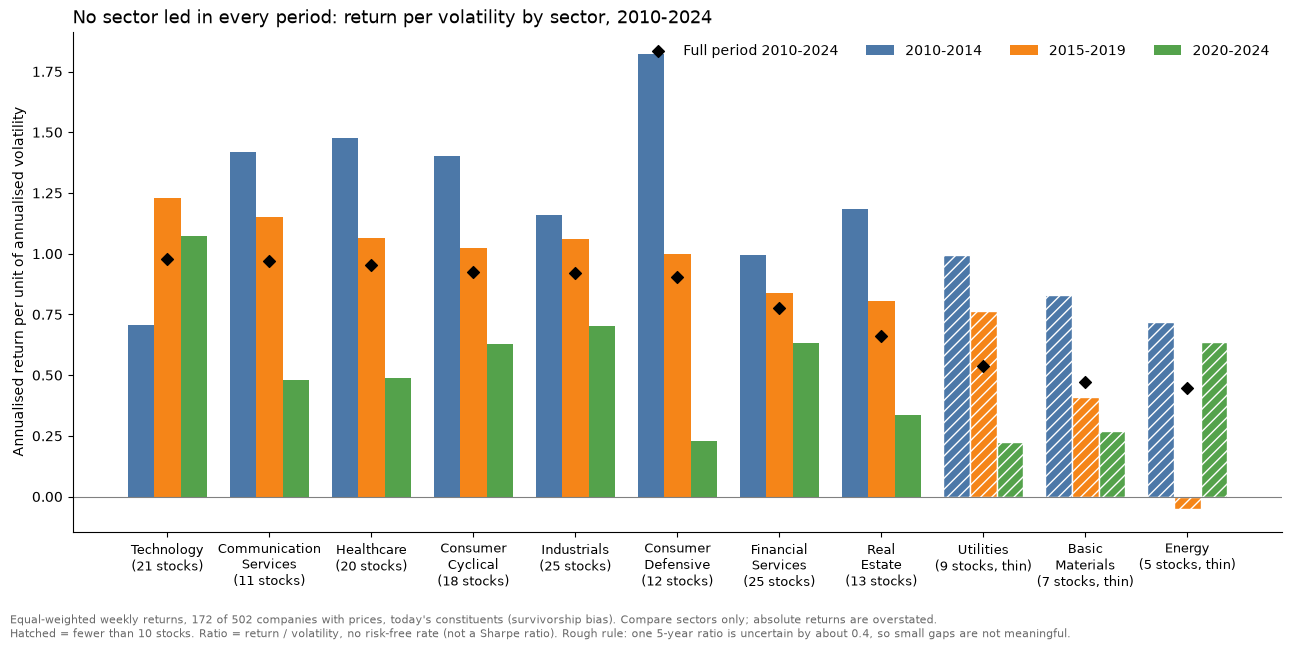

In [17]:
order = ratio["full"].sort_values(ascending=False).index.tolist()
x = np.arange(len(order))
width = 0.26
colors = {"2010-2014": "#4C78A8", "2015-2019": "#F58518", "2020-2024": "#54A24B"}

fig, ax = plt.subplots(figsize=(13, 6.5))
for i, sp in enumerate(SUB_PERIODS):
    vals = ratio.loc[order, sp].values
    bars = ax.bar(x + (i - 1) * width, vals, width, label=sp, color=colors[sp])
    for b, sector in zip(bars, order):
        if stocks[sector] < THIN_BELOW:
            b.set_hatch("///")
            b.set_edgecolor("white")

ax.scatter(x, ratio.loc[order, "full"].values, marker="D", color="black", zorder=5, label="Full period 2010-2024")
ax.axhline(0, color="grey", linewidth=0.8)

labels = [s.replace(" ", "\n", 1) + f"\n({stocks[s]} stocks{', thin' if stocks[s] < THIN_BELOW else ''})" for s in order]
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Annualised return per unit of annualised volatility")
ax.set_title("No sector led in every period: return per volatility by sector, 2010-2024", loc="left", fontsize=13)
ax.legend(frameon=False, ncol=4, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.005,
         "Equal-weighted weekly returns, 172 of 502 companies with prices, today's constituents (survivorship bias). "
         "Compare sectors only; absolute returns are overstated.\n"
         "Hatched = fewer than 10 stocks. Ratio = return / volatility, no risk-free rate (not a Sharpe ratio). "
         "Rough rule: one 5-year ratio is uncertain by about 0.4, so small gaps are not meaningful.",
         fontsize=8, color="dimgrey", va="bottom")
fig.tight_layout(rect=(0, 0.06, 1, 1))
Path("output").mkdir(exist_ok=True)
fig.savefig("output/return_per_volatility_by_sector.png", dpi=200)
plt.show()

## Notes for the memo
- Results above are historical and describe these 172 stocks only.
- Sector membership changes between sub-periods, so changes over time mix real sector behaviour with a different set of stocks.
- The data cannot say why 330 companies have no prices.

In [18]:
print("cwd:", Path.cwd())
print(WEEKLY_CSV.resolve(), WEEKLY_CSV.exists())
print(MART_CSV.resolve(), MART_CSV.exists())

cwd: c:\Projects\dbt_sp500_stocks\notebooks
C:\Projects\dbt_sp500_stocks\data\fct_sector_weekly_returns.csv True
C:\Projects\dbt_sp500_stocks\data\mart_sector_risk_return.csv True
